# Data Science Fundamentals Assessment
## B.Pharm → Data Analytics | Synthetic pharmacy operations

**Educational only:** 120 fictional independent sites, deliberately injected defects, no patient records. Each site has one summary observation. The generator includes a workflow effect; statistical results are not real-world evidence.

Run cells from top to bottom. The submitted notebook includes actual executed outputs. CSV formats cannot preserve Pandas categories; `load_cleaned()` restores them. Setup reruns analysis against the supplied raw CSV without altering it.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Start Jupyter in the repository root or notebooks folder.')
sys.path.insert(0, str(ROOT / 'src'))
from pharmacy_ds.pipeline import run_pipeline

_ = run_pipeline(ROOT, include_exercises=False)

SYNTHETIC PHARMACY OPERATIONS — EXECUTED RESULTS
Clean sites: 117; observed wait outcomes: 111
Wait mean = 8.147 min; median = 8.150 min
Sample variance = 2.732 min^2; sample SD = 1.653 min
Standard: n=55, mean=8.678, SD=1.309 min
Barcode-assisted: n=56, mean=7.625, SD=1.795 min
Welch difference (Standard - Barcode-assisted) = 1.054 min
95% CI = [0.463, 1.644] min
t=3.5375, df=100.657, p=0.000612561
At alpha=0.05: Reject H0 (simulation only; not a clinical claim).
Workload vs wait: n=101, r=0.4842, covariance=18.6331
P(site mean wait < 10 min | observed) = 99/111 = 0.8919
Missing wait outcomes were NOT imputed; correlation excludes imputed workload inputs.
This dataset is fictional and its generating formula includes a workflow effect.
Figures saved: 7


## 01 · Variables and basic types

**Task:** Store a fictional medicine label, stock count, unit price and Boolean flag; compute inventory value.

**Why it matters:** Use a string for names, an integer for counts, a float for measurements or illustrative prices, and a Boolean for yes/no flags. Production financial calculations should use Decimal or integer paise to avoid binary floating-point rounding.

In [2]:
"""Task 01: variables, basic types and pharmacy stock arithmetic."""

medicine = "Paracetamol (fictional stock item)"
stock_units = 120
unit_price_inr = 2.50
requires_cold_chain = False
print(f"Medicine: {medicine}")
print(
    f"Types: {type(medicine).__name__}, {type(stock_units).__name__}, "
    f"{type(unit_price_inr).__name__}, {type(requires_cold_chain).__name__}"
)
print(f"Inventory value: INR {stock_units * unit_price_inr:.2f}")
print(f"After selling 15 units: {stock_units - 15} units")


Medicine: Paracetamol (fictional stock item)
Types: str, int, float, bool
Inventory value: INR 300.00
After selling 15 units: 105 units


## 02 · Lists, tuples, sets and dictionaries

**Task:** Organize stock items with four built-in collection types and inspect their behavior.

**Why it matters:** Lists are ordered and mutable; tuples are ordered and immutable; sets keep unique hashable members without a dependable display order; dictionaries map unique keys to values and preserve insertion order. The storage-range tuple is fictional, not product storage guidance.

In [3]:
"""Task 02: list, tuple, set and dictionary; print sets in a stable order."""

medicines = ["Antacid", "ORS", "Antacid"]
medicines.append("Bandage")
storage_range_c = (15, 25)  # A fictional tuple, not storage advice.
unique_items = set(medicines)
stock = {"Antacid": 50, "ORS": 30, "Bandage": 20}
print("List:", medicines)
print("Tuple:", storage_range_c)
print("Unique items:", sorted(unique_items))
print("ORS stock:", stock["ORS"])
print("Dictionary keys:", sorted(stock))
print("List slice:", medicines[:2])


List: ['Antacid', 'ORS', 'Antacid', 'Bandage']
Tuple: (15, 25)
Unique items: ['Antacid', 'Bandage', 'ORS']
ORS stock: 30
Dictionary keys: ['Antacid', 'Bandage', 'ORS']
List slice: ['Antacid', 'ORS']


## 03 · Conditions and loops

**Task:** Assign stock status with if/elif/else and use for, while and a list comprehension.

**Why it matters:** Condition order matters: zero stock is checked before the low-stock rule. The while loop decreases a counter every iteration, guaranteeing termination. The reorder threshold is a teaching rule, not a validated pharmacy policy.

In [4]:
"""Task 03: if/elif/else, for and while loops with explicit stopping rules."""

stock = {"Antacid": 50, "ORS": 12, "Bandage": 0}
for item, units in stock.items():
    if units == 0:
        status = "Out of stock"
    elif units < 20:
        status = "Reorder"
    else:
        status = "Adequate"
    print(f"{item}: {status}")

remaining = 12
steps = 0
while remaining > 0:
    remaining -= min(5, remaining)
    steps += 1
print(f"While loop: {steps} steps; {remaining} units remaining")
print("Low-stock items:", [item for item, units in stock.items() if units < 20])


Antacid: Adequate
ORS: Reorder
Bandage: Out of stock
While loop: 3 steps; 0 units remaining
Low-stock items: ['ORS', 'Bandage']


## 04 · Functions and exception handling

**Task:** Define a documented function, return a result, reject negative input, and catch conversion failures.

**Why it matters:** Functions reduce duplication. Type hints document intended types but do not enforce them at runtime. Catch specific expected exceptions; do not silently ignore invalid input. The small arithmetic function illustrates a concept; the data pipeline adds finite-number, integer and range validation.

In [5]:
"""Task 04: a reusable function, a docstring and specific exception handling."""


def inventory_value(units: int, price: float) -> float:
    """Return INR stock value for non-negative units and unit price."""
    if units < 0 or price < 0:
        raise ValueError("Units and price cannot be negative.")
    return units * price


print(f"Valid value: INR {inventory_value(120, 2.5):.2f}")
try:
    inventory_value(-5, 2.5)
except ValueError as error:
    print("Handled validation error:", error)

try:
    units = int("twelve")
except ValueError:
    print("Handled conversion error: enter a whole number, for example 12.")
finally:
    print("Input check completed.")


Valid value: INR 300.00
Handled validation error: Units and price cannot be negative.
Handled conversion error: enter a whole number, for example 12.
Input check completed.


## 05 · NumPy basics

**Task:** Build and slice arrays, apply vectorized arithmetic, compute sample variation and aggregate over an axis.

**Why it matters:** NumPy arrays normally share a numeric dtype and support efficient elementwise operations. axis=0 aggregates down rows into column totals. NumPy defaults to population variance/SD (ddof=0); pass ddof=1 when estimating sample variation.

In [6]:
"""Task 05: array construction, slicing, vectorization, axes and ddof."""

import numpy as np

sales = np.array([10, 12, 8, 15, 5])
print("Array:", sales.tolist())
print("First three:", sales[:3].tolist())
print("After adding 2:", (sales + 2).tolist())
print(f"Mean={sales.mean():.2f}; sample SD={sales.std(ddof=1):.3f}")
matrix = np.array([[10, 12], [8, 15], [5, 10]])
print("Shape:", matrix.shape)
print("Column totals (axis=0):", matrix.sum(axis=0).tolist())


Array: [10, 12, 8, 15, 5]
First three: [10, 12, 8]
After adding 2: [12, 14, 10, 17, 7]
Mean=10.00; sample SD=3.808
Shape: (3, 2)
Column totals (axis=0): [23, 37]


## 06 · Pandas basics

**Task:** Create a DataFrame, select a Series, filter rows with .loc, calculate a column and group values.

**Why it matters:** A Series is one labeled column; a DataFrame is a labeled table. Boolean filtering and groupby avoid error-prone row-by-row loops. Use explicit .loc assignment rather than chained indexing.

In [7]:
"""Task 06: DataFrame, Series, filtering, .loc, derived columns and groupby."""

import pandas as pd

stock = pd.DataFrame(
    {
        "item": ["Antacid", "ORS", "Bandage"],
        "category": ["Medicine", "Medicine", "Supply"],
        "units": [50, 12, 20],
        "unit_price_inr": [3.0, 5.0, 8.0],
    }
)
stock["value_inr"] = stock["units"] * stock["unit_price_inr"]
print("Shape:", stock.shape)
print("Units Series:", stock["units"].tolist())
print("Filtered rows:")
print(stock.loc[stock["units"] < 20, ["item", "units"]].to_string(index=False))
print("Value by category:")
print(stock.groupby("category")["value_inr"].sum().to_string())


Shape: (3, 5)
Units Series: [50, 12, 20]
Filtered rows:
item  units
 ORS     12
Value by category:
category
Medicine    210.0
Supply      160.0


## 07 · Missing values, duplicates and cleaning

**Task:** Clean the supplied CSV, quarantine critical defects and inspect the imputation audit.

**Why it matters:** Keep raw data unchanged. Remove only exact duplicate records. Unrecognized workflow, invalid date and invalid ID are not guessed. Numeric predictors use flagged median imputation; count medians are rounded to whole numbers. Missing wait outcomes remain missing. Full implementation: src/pharmacy_ds/cleaning.py.

In [8]:
"""Task 07: run audited cleaning without changing the raw CSV."""

import pandas as pd

from pharmacy_ds.cleaning import clean_data
from pharmacy_ds.config import PROJECT_ROOT

raw = pd.read_csv(PROJECT_ROOT / "data/raw/pharmacy_operations_dirty.csv")
clean, rejected, audit = clean_data(raw)
print(f"Input rows: {len(raw)}")
print(f"Exact duplicates removed: {audit['exact_duplicates_removed']}")
print(f"Critical rows quarantined: {len(rejected)}")
print(f"Clean rows: {len(clean)}")
print("Imputed numeric cells (with flags):")
for column, count in audit["imputed_counts"].items():
    print(f"  {column}: {count}; fill={audit['imputation_values'][column]}")
print(f"Unknown regions: {audit['unknown_region_count']}")
print(f"Missing wait outcomes retained: {audit['missing_wait_outcomes_retained']}")
print("Validation passed; no outcome was imputed.")


Input rows: 125
Exact duplicates removed: 5
Critical rows quarantined: 3
Clean rows: 117
Imputed numeric cells (with flags):
  daily_prescriptions: 6; fill=147
  staff_on_duty: 4; fill=4
  stock_availability_pct: 4; fill=93.26
  inventory_value_inr: 3; fill=37380.83
  expired_units: 0; fill=2
Unknown regions: 3
Missing wait outcomes retained: 6
Validation passed; no outcome was imputed.


## 08 · Analytical data types

**Task:** Inspect storage dtypes and preserve a meaningful ordinal category order.

**Why it matters:** Numerical versus categorical is a semantic distinction, not merely a storage dtype. Pharmacy identifiers are nominal labels; wait is continuous; prescriptions are discrete; risk is ordinal. A CSV is structured while natural-language notes within it contain unstructured content.

In [9]:
"""Task 08: analytical data types versus Python/Pandas storage types."""

from pharmacy_ds.cleaning import load_cleaned
from pharmacy_ds.config import PROJECT_ROOT

df = load_cleaned(PROJECT_ROOT / "data/processed/pharmacy_operations_clean.csv")
for column in [
    "pharmacy_id",
    "report_date",
    "workflow",
    "stock_risk",
    "daily_prescriptions",
    "mean_wait_minutes",
    "notes",
]:
    print(f"{column}: {df[column].dtype}")
print("Risk order:", df["stock_risk"].cat.categories.tolist())
print("Risk is ordered:", df["stock_risk"].cat.ordered)
print("CSV = structured table; notes content = unstructured text.")
print("An ID is nominal even when it contains digits.")


pharmacy_id: string
report_date: datetime64[ns]
workflow: category
stock_risk: category
daily_prescriptions: int64
mean_wait_minutes: float64
notes: string
Risk order: ['Low', 'Medium', 'High']
Risk is ordered: True
CSV = structured table; notes content = unstructured text.
An ID is nominal even when it contains digits.


## 09 · Exploratory data analysis

**Task:** Compare workflow summaries, count risk categories and flag possible outliers without deleting them.

**Why it matters:** EDA examines distributions, missingness, relationships and surprising values before modeling. Summary denominators reflect observed outcomes. Risk counts are descriptive and include flagged stock imputations. An IQR flag is a prompt for investigation, not proof of an error.

In [10]:
"""Task 09: explore groups, category counts and potential (not deleted) outliers."""

from pharmacy_ds.cleaning import load_cleaned
from pharmacy_ds.config import PROJECT_ROOT

df = load_cleaned(PROJECT_ROOT / "data/processed/pharmacy_operations_clean.csv")
print("Observed site waits by workflow:")
table = df.groupby("workflow", observed=True)["mean_wait_minutes"].agg(
    ["count", "mean", "median", "std"]
)
print(table.to_string(float_format=lambda number: f"{number:.3f}"))
print("Derived risk counts (include stock imputations):")
print(df["stock_risk"].value_counts(sort=False).to_string())
wait = df["mean_wait_minutes"].dropna()
q1, q3 = wait.quantile([0.25, 0.75])
iqr = q3 - q1
flag = (wait < q1 - 1.5 * iqr) | (wait > q3 + 1.5 * iqr)
print(f"IQR-fence potential wait outliers: {int(flag.sum())}; retained for analysis")


Observed site waits by workflow:
                  count  mean  median   std
workflow                                   
Barcode-assisted     56 7.625   7.555 1.795
Standard             55 8.678   8.710 1.309
Derived risk counts (include stock imputations):
stock_risk
Low       36
Medium    74
High       7
IQR-fence potential wait outliers: 4; retained for analysis


## 10 · Mean, median, mode, variance and SD

**Task:** Verify a small hand-checkable dataset and compute sample statistics for site mean waits.

**Why it matters:** The mean is sensitive to extreme values; the median describes the middle; the mode is most useful for categories or repeated discrete values. Sample variance uses n−1 and squared units; SD returns to the original units. Site mean wait is not the mean of all patient waiting times.

In [11]:
"""Task 10: a hand-checkable example plus statistics on observed site waits."""

import numpy as np
from scipy import stats

from pharmacy_ds.cleaning import load_cleaned
from pharmacy_ds.config import PROJECT_ROOT

values = np.array([2, 4, 4, 4, 5, 5, 7, 9])
print(f"Toy mean={np.mean(values):.3f}; median={np.median(values):.3f}")
print(f"Toy mode={int(stats.mode(values, keepdims=False).mode)}")
print(f"Toy population variance={np.var(values, ddof=0):.3f}")
print(f"Toy sample variance={np.var(values, ddof=1):.3f}")
print(f"Toy sample SD={np.std(values, ddof=1):.3f}")
df = load_cleaned(PROJECT_ROOT / "data/processed/pharmacy_operations_clean.csv")
y = df["mean_wait_minutes"].dropna()
print(f"Observed site waits: n={len(y)}, mean={y.mean():.3f}, median={y.median():.3f}")
print(f"Sample variance={y.var(ddof=1):.3f}; sample SD={y.std(ddof=1):.3f}")
print(
    "Staff modes (descriptive; includes imputations):",
    df["staff_on_duty"].mode().tolist(),
)


Toy mean=5.000; median=4.500
Toy mode=4
Toy population variance=4.000
Toy sample variance=4.571
Toy sample SD=2.138
Observed site waits: n=111, mean=8.147, median=8.150
Sample variance=2.732; sample SD=1.653
Staff modes (descriptive; includes imputations): [4]


## 11 · Probability and the normal distribution

**Task:** Calculate pack-selection probabilities, empirical site-level probabilities and a hypothetical normal-model probability.

**Why it matters:** With-replacement draws can be independent; without-replacement draws change the second probability. Empirical probabilities use only records with observed outcomes. X ~ N(10, 2²) is a separate assumed model, not a normality claim about the pharmacy dataset.

In [12]:
"""Task 11: empirical, conditional and model-based probabilities."""

from scipy import stats

from pharmacy_ds.cleaning import load_cleaned
from pharmacy_ds.config import PROJECT_ROOT

print(f"3 damaged packs out of 20: P(damaged)={3 / 20:.4f}")
print(f"Two damaged, with replacement: {(3 / 20) ** 2:.4f}")
print(f"Two damaged, without replacement: {(3 / 20) * (2 / 19):.4f}")
df = load_cleaned(PROJECT_ROOT / "data/processed/pharmacy_operations_clean.csv")
observed = df.dropna(subset=["mean_wait_minutes"])
successes = int(observed["mean_wait_minutes"].lt(10).sum())
print(
    f"P(site mean wait < 10 | observed)={successes}/{len(observed)}={successes / len(observed):.4f}"
)
for workflow in ["Standard", "Barcode-assisted"]:
    group = observed.loc[observed["workflow"].eq(workflow), "mean_wait_minutes"]
    print(f"P(site mean wait < 10 | {workflow})={group.lt(10).mean():.4f}")
print("Hypothetical normal model: X ~ N(10, 2^2); not fitted to these data")
print(f"z at X=12: {(12 - 10) / 2:.1f}")
print(f"P(X <= 12)={stats.norm.cdf(12, loc=10, scale=2):.4f}")
print(f"P(8 <= X <= 12)={stats.norm.cdf(12, 10, 2) - stats.norm.cdf(8, 10, 2):.4f}")


3 damaged packs out of 20: P(damaged)=0.1500
Two damaged, with replacement: 0.0225
Two damaged, without replacement: 0.0158
P(site mean wait < 10 | observed)=99/111=0.8919
P(site mean wait < 10 | Standard)=0.8727
P(site mean wait < 10 | Barcode-assisted)=0.9107
Hypothetical normal model: X ~ N(10, 2^2); not fitted to these data
z at X=12: 1.0
P(X <= 12)=0.8413
P(8 <= X <= 12)=0.6827


## 12 · Correlation and covariance

**Task:** Use observed workload inputs to calculate a paired sample covariance and Pearson r.

**Why it matters:** Covariance has product units and depends on scale; Pearson r is unitless in [−1, 1] and measures linear association. Neither establishes causation. Workflow differences, nonlinearity or outliers can affect the pooled association.

In [13]:
"""Task 12: observed-only sample covariance and Pearson correlation."""

from pharmacy_ds.cleaning import load_cleaned
from pharmacy_ds.config import PROJECT_ROOT
from pharmacy_ds.statistics import correlation_sample

df = load_cleaned(PROJECT_ROOT / "data/processed/pharmacy_operations_clean.csv")
observed = correlation_sample(df)
x = observed["workload_per_staff"]
y = observed["mean_wait_minutes"]
print(f"Complete observed workload/wait pairs: {len(observed)}")
print(f"Sample covariance: {x.cov(y, ddof=1):.4f}")
print("Covariance units: (prescriptions per staff member) * minutes")
print(f"Pearson correlation r: {x.corr(y):.4f}")
print("Correlation does not establish causation; workflow is a possible confounder.")


Complete observed workload/wait pairs: 101
Sample covariance: 18.6331
Covariance units: (prescriptions per staff member) * minutes
Pearson correlation r: 0.4842
Correlation does not establish causation; workflow is a possible confounder.


## 13 · Hypothesis testing

**Task:** Compare independent pharmacy-level mean waits with a two-sided Welch test and a 95% confidence interval.

**Why it matters:** Prespecify H0, H1 and alpha. Welch does not require equal variances but still needs independent observations and an adequately behaved sampling distribution. Inspect within-group Q–Q plots and Shapiro diagnostics; a nonsignificant normality test does not prove normality. The simulated effect was built into the generator.

In [14]:
"""Task 13: two-sided Welch test, confidence interval and normality diagnostics."""

from pharmacy_ds.cleaning import load_cleaned
from pharmacy_ds.config import PROJECT_ROOT
from pharmacy_ds.statistics import analyze

df = load_cleaned(PROJECT_ROOT / "data/processed/pharmacy_operations_clean.csv")
result = analyze(df)
test = result["welch_test"]
print("H0: Standard and Barcode-assisted population mean site waits are equal.")
print("H1: They differ. Prespecified alpha=0.05; two-sided Welch test.")
for name, group in result["workflow_summary"].items():
    print(
        f"{name}: n={group['n']}, mean={group['mean']:.3f}, SD={group['sample_sd']:.3f}"
    )
    print(f"  Shapiro-Wilk W={group['shapiro_w']:.4f}, p={group['shapiro_p']:.4f}")
print(f"Difference (Standard - Barcode-assisted)={test['difference_minutes']:.3f} min")
print(f"95% CI=[{test['ci95_low']:.3f}, {test['ci95_high']:.3f}] min")
print(
    f"Welch t={test['t_statistic']:.4f}; df={test['degrees_of_freedom']:.3f}; p={test['p_value']:.6g}"
)
print(f"Decision: {test['decision']}")
print(
    "Independent simulated sites; no imputed outcomes. Simulation is not clinical evidence."
)


H0: Standard and Barcode-assisted population mean site waits are equal.
H1: They differ. Prespecified alpha=0.05; two-sided Welch test.
Standard: n=55, mean=8.678, SD=1.309
  Shapiro-Wilk W=0.9857, p=0.7558
Barcode-assisted: n=56, mean=7.625, SD=1.795
  Shapiro-Wilk W=0.9668, p=0.1247
Difference (Standard - Barcode-assisted)=1.054 min
95% CI=[0.463, 1.644] min
Welch t=3.5375; df=100.657; p=0.000612561
Decision: Reject H0
Independent simulated sites; no imputed outcomes. Simulation is not clinical evidence.


## 14 · Data visualization

**Task:** Regenerate seven clearly labeled PNG charts and verify the saved file names.

**Why it matters:** Choose a histogram for a distribution, a box plot for group spreads, a scatter plot for two numerical variables, and a bar chart for categories. Q–Q plots assess shape within each workflow. Label axes, units, sample definitions and imputation policy. Actual images appear in the EDA section and executed notebook.

In [15]:
"""Task 14: regenerate seven labeled chart files using Matplotlib and Seaborn."""

import pandas as pd

from pharmacy_ds.cleaning import load_cleaned
from pharmacy_ds.config import PROJECT_ROOT
from pharmacy_ds.visualization import create_figures

raw = pd.read_csv(PROJECT_ROOT / "data/raw/pharmacy_operations_dirty.csv")
df = load_cleaned(PROJECT_ROOT / "data/processed/pharmacy_operations_clean.csv")
paths = create_figures(raw, df, PROJECT_ROOT / "reports/figures")
print(f"Saved {len(paths)} figures:")
for path in paths:
    print(" ", path.relative_to(PROJECT_ROOT).as_posix())


Saved 7 figures:
  reports/figures/01_wait_histogram.png
  reports/figures/02_wait_by_workflow.png
  reports/figures/03_workload_scatter.png
  reports/figures/04_stock_risk_counts.png
  reports/figures/05_raw_missingness.png
  reports/figures/06_qq_standard.png
  reports/figures/07_qq_barcode.png


## 15 · Data validation and safe failure

**Task:** Introduce three common integrity errors and confirm they raise useful validation errors.

**Why it matters:** Validation guards against silently producing misleading results. Production code checks required columns, valid IDs, dates, uniqueness, finite numbers, integer counts, ranges and consistency of derived variables. Expected failures are caught and explained; unexpected failures should stop the run.

In [16]:
"""Task 15: deliberately break data and prove that validation rejects it."""

from pharmacy_ds.cleaning import DataValidationError, load_cleaned, validate_clean_data
from pharmacy_ds.config import PROJECT_ROOT

df = load_cleaned(PROJECT_ROOT / "data/processed/pharmacy_operations_clean.csv")
for scenario in ["negative inventory", "duplicate ID", "missing column"]:
    bad = df.copy()
    if scenario == "negative inventory":
        bad.loc[0, "inventory_value_inr"] = -1
    elif scenario == "duplicate ID":
        bad.loc[1, "pharmacy_id"] = bad.loc[0, "pharmacy_id"]
    else:
        bad = bad.drop(columns=["workflow"])
    try:
        validate_clean_data(bad)
    except DataValidationError as error:
        print(f"Rejected {scenario}: {error}")


Rejected negative inventory: inventory_value_inr cannot contain negative values.
Rejected duplicate ID: pharmacy_id must be unique.
Rejected missing column: Missing required columns: workflow


## 16 · Git version control

**Task:** Run staging, a local commit, history inspection and a clean-status check in a disposable repository.

**Why it matters:** Git records local history; GitHub hosts remote repositories. This is a real local Git demonstration with a fixed demonstration identity/date, not an authenticated GitHub upload. Review staged changes, use focused commits and never commit credentials. The temporary repository is removed after the exercise.

In [17]:
"""Task 16: execute Git staging, a local commit and history in a disposable repo."""

from pharmacy_ds.git_demo import run_git_demo

print(run_git_demo(), end="")


$ git init --quiet -b main
$ git add README.md
$ git diff --cached --stat
README.md | 1 +
 1 file changed, 1 insertion(+)
$ git -c commit.gpgsign=false commit --quiet -m Add assessment README
$ git log -1 --oneline
2cd2c5e Add assessment README
$ git status --short
Clean working tree; local demonstration only. No GitHub repository was created.


## EDA visual evidence

Images below are embedded outputs, not remote resources. Wait plots use observed outcomes. The scatter excludes imputed workload inputs; risk counts include flagged stock imputations. Q–Q plots examine each workflow separately.

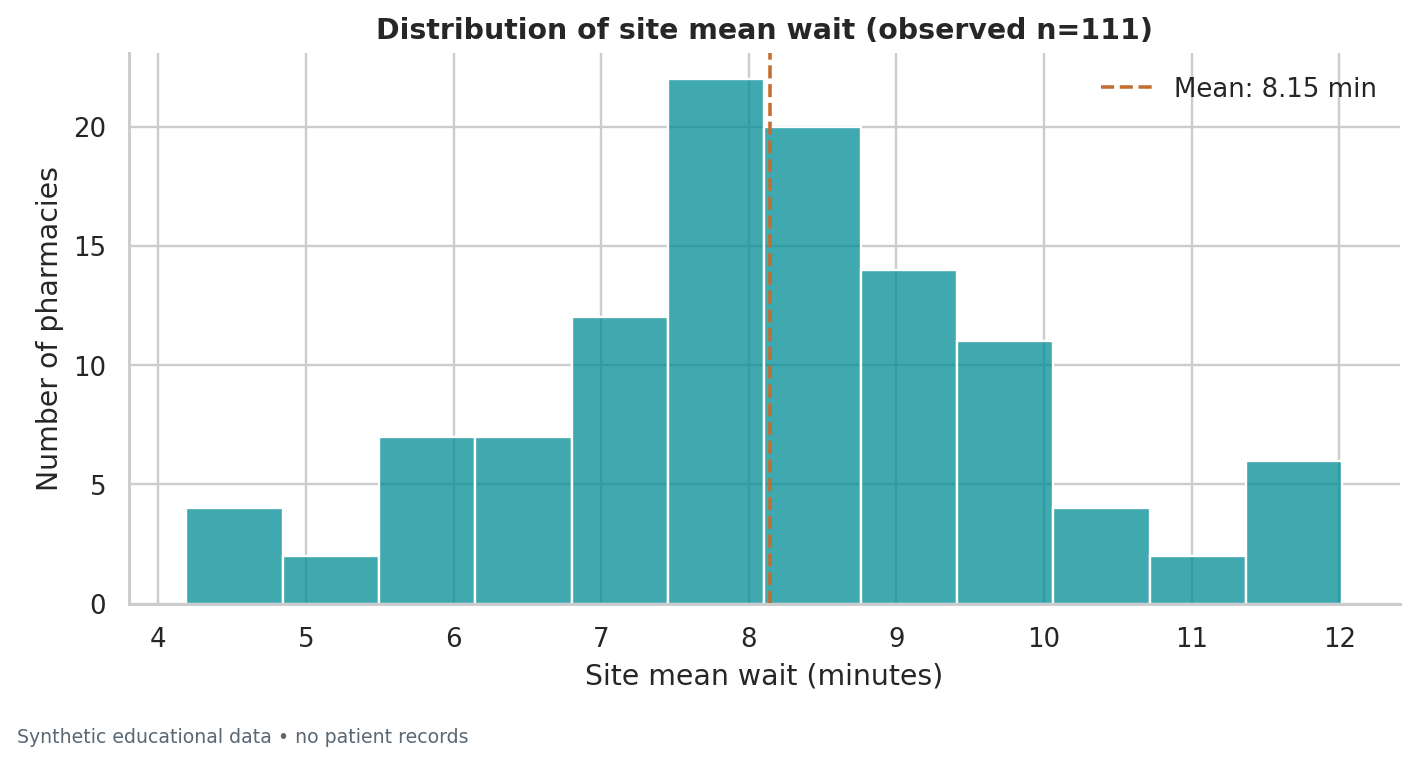

In [18]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / 'reports/figures/01_wait_histogram.png')))

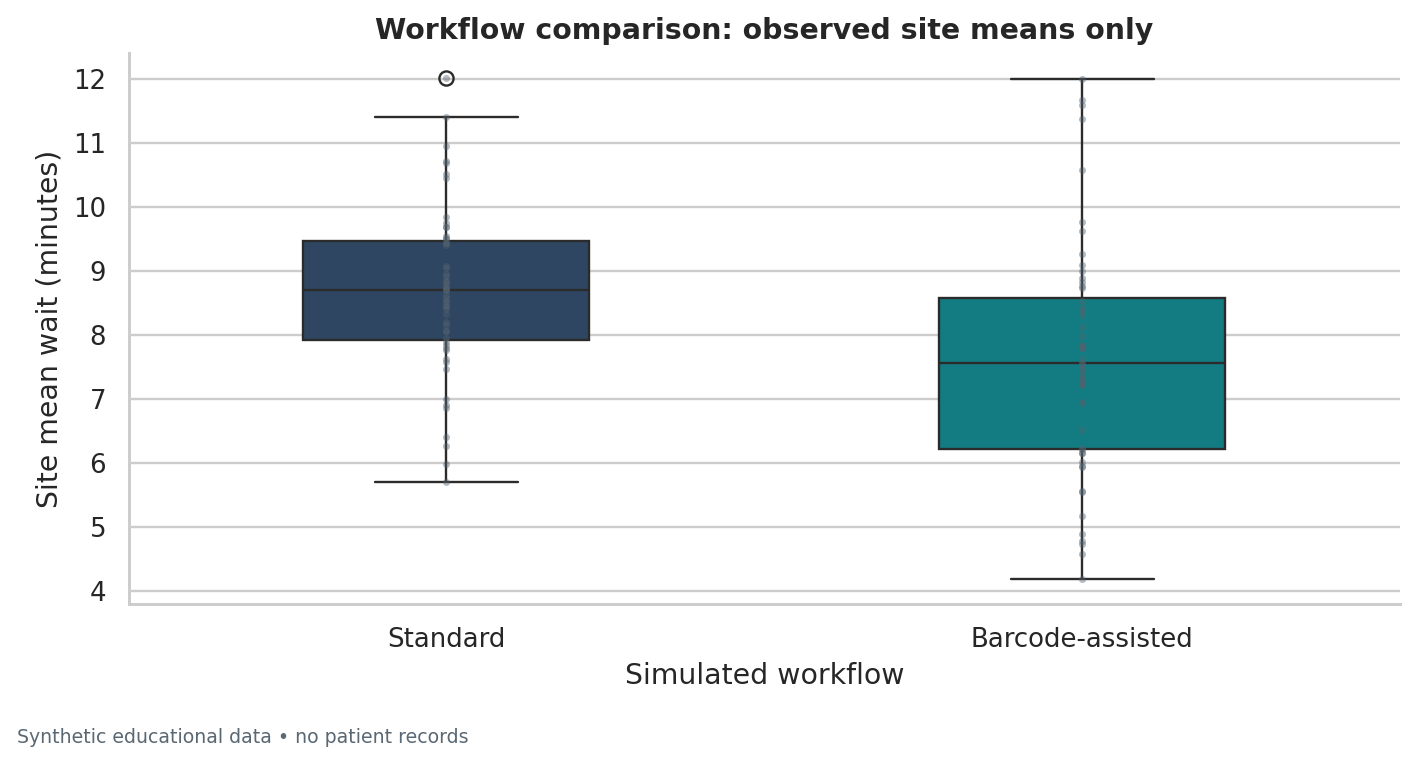

In [19]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / 'reports/figures/02_wait_by_workflow.png')))

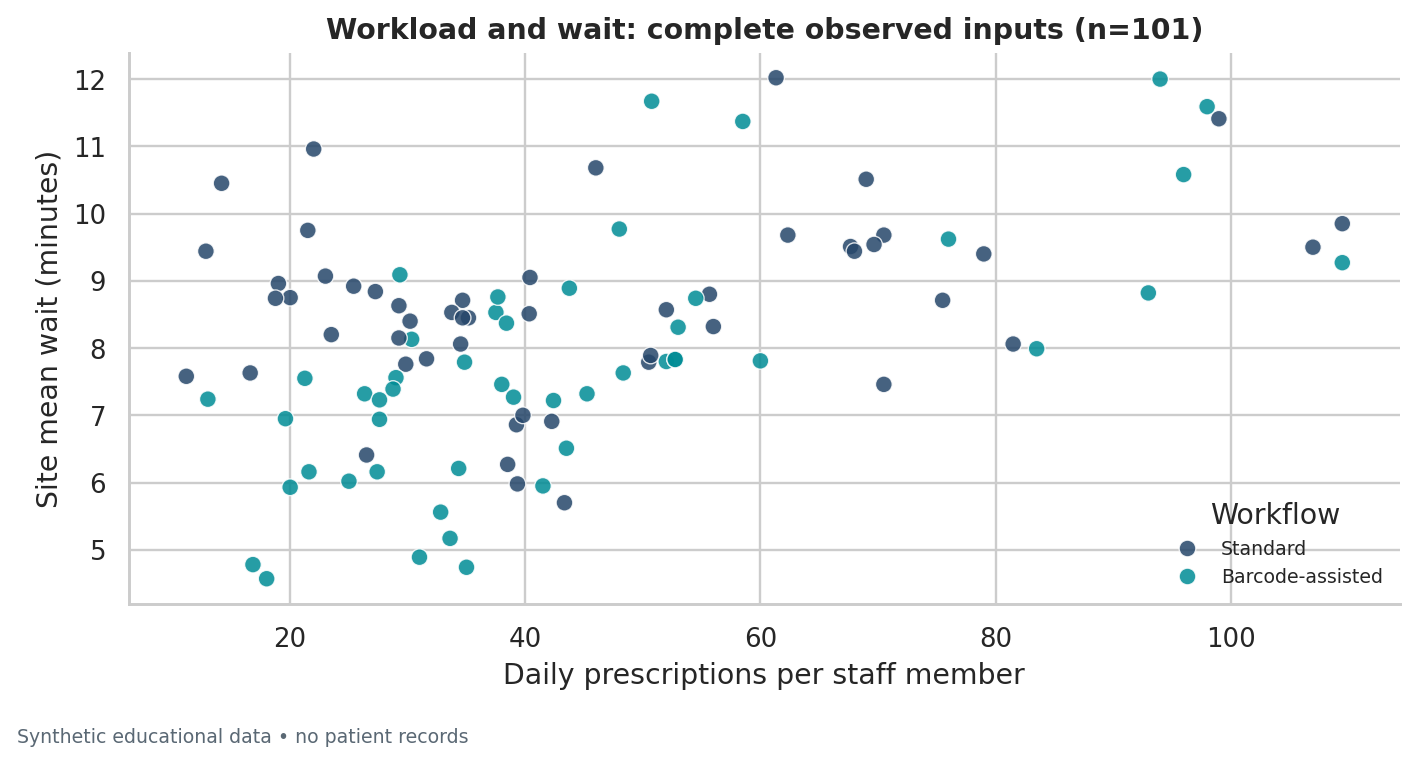

In [20]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / 'reports/figures/03_workload_scatter.png')))

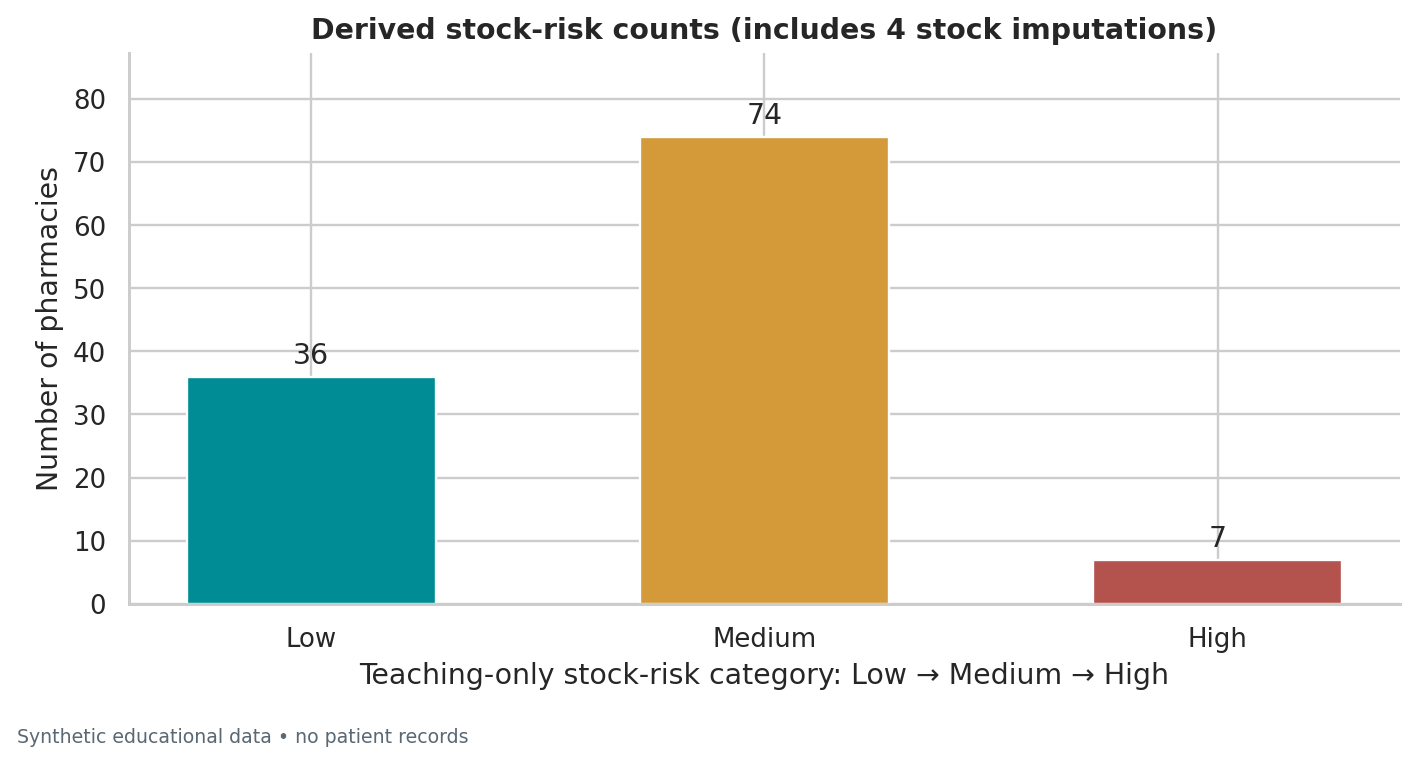

In [21]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / 'reports/figures/04_stock_risk_counts.png')))

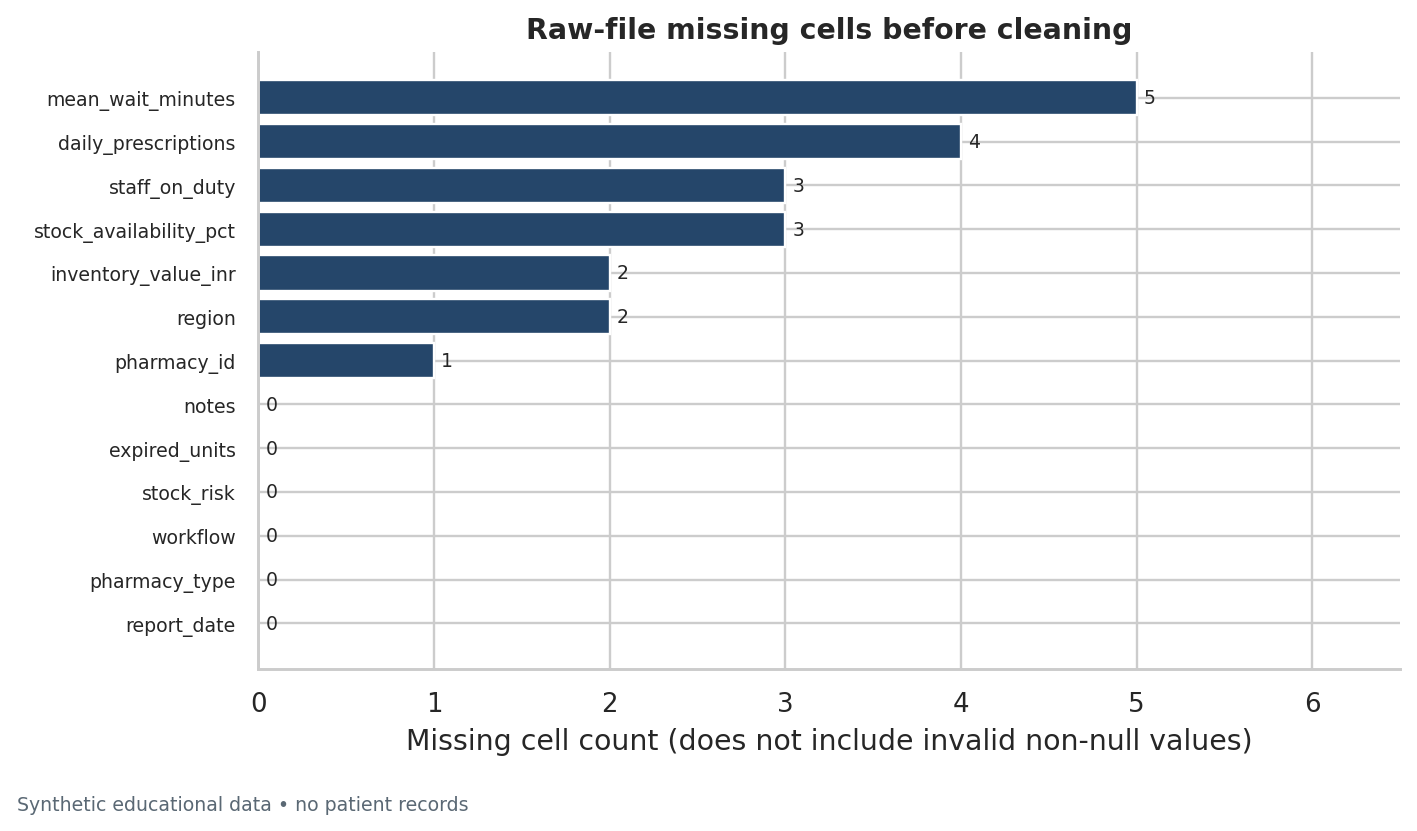

In [22]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / 'reports/figures/05_raw_missingness.png')))

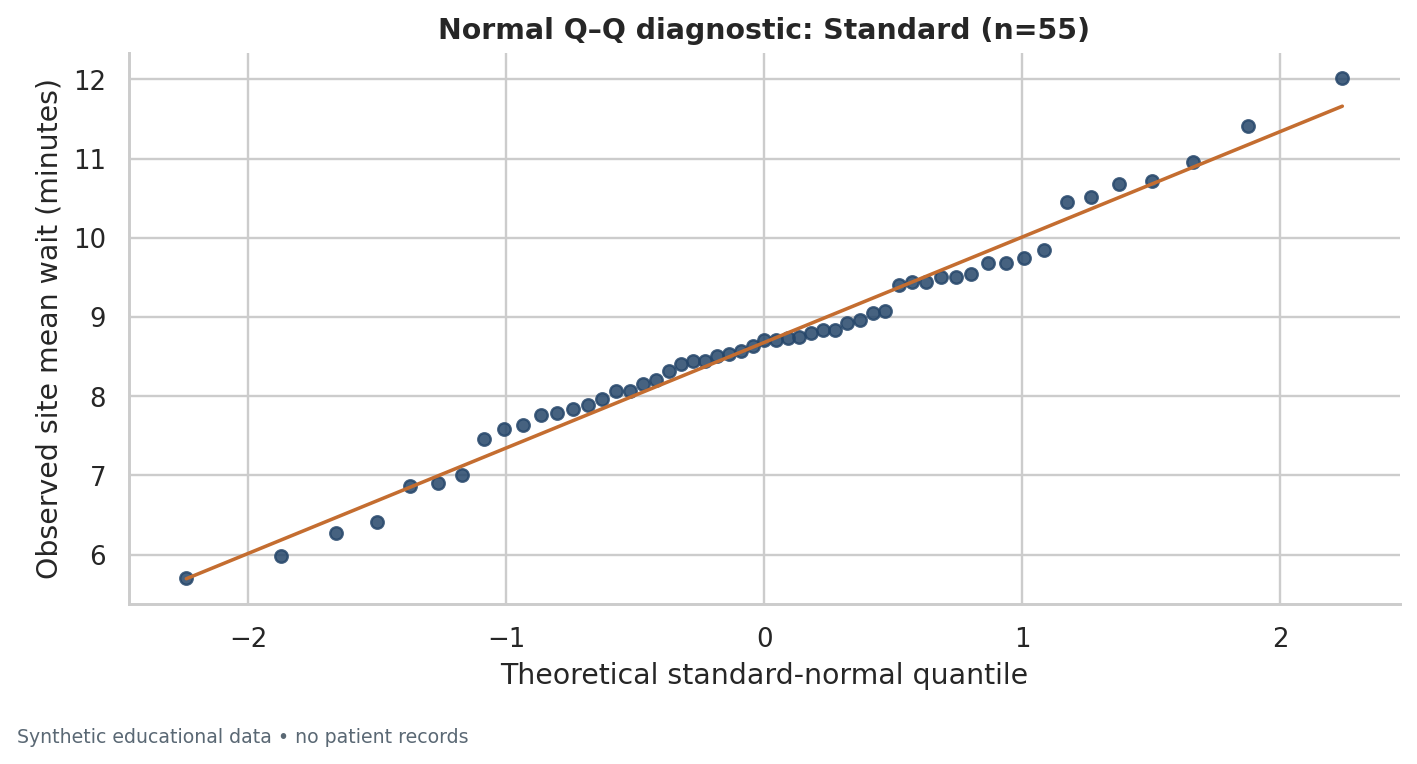

In [23]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / 'reports/figures/06_qq_standard.png')))

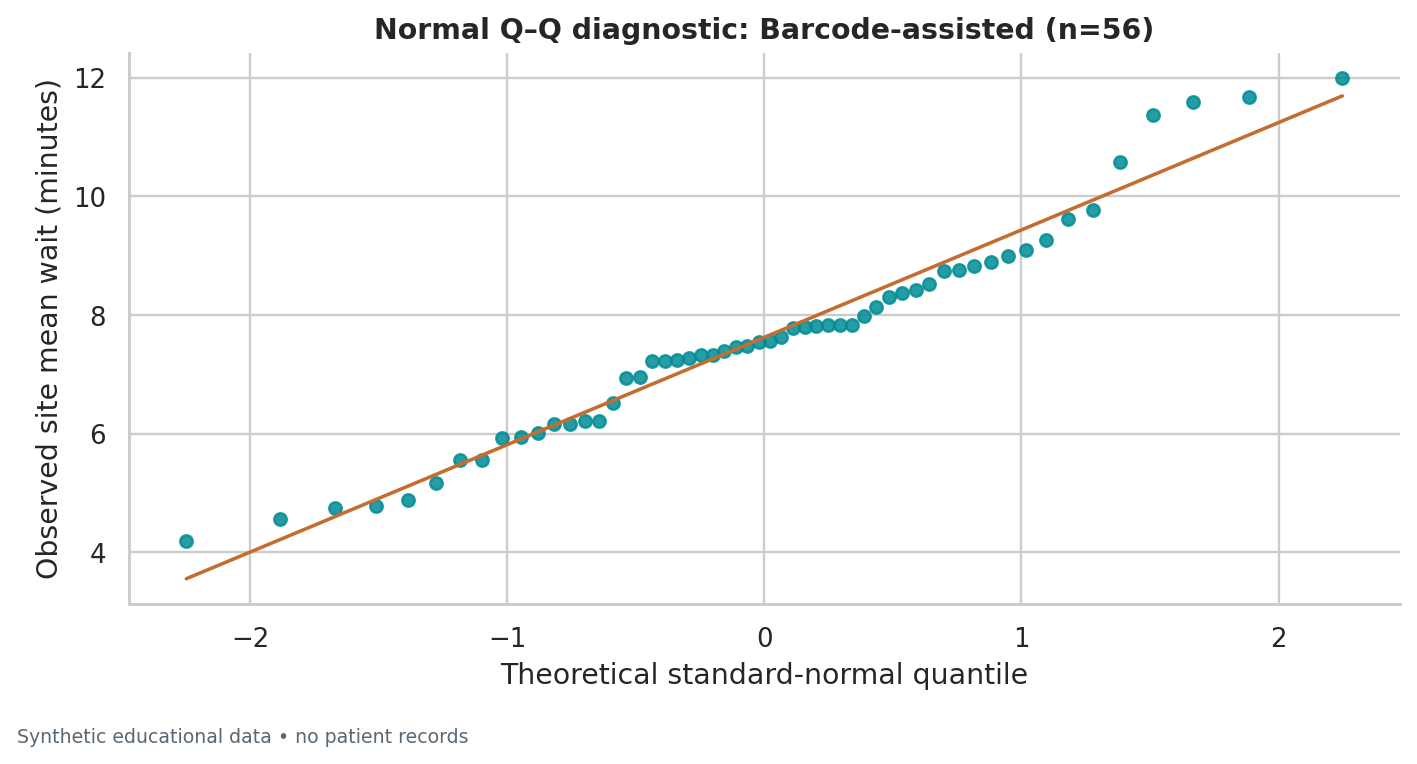

In [24]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / 'reports/figures/07_qq_barcode.png')))

## Interpretation and integrity

The Welch test compares pharmacy-level mean waits, **not individual waiting times**. Missing outcomes are not imputed; correlation uses complete observed inputs. Inspect `reports/statistical_results.json`, `reports/cleaning_audit.json` and `reports/test_results.txt` for reproducible evidence. No GitHub publishing occurs in this notebook. References and limitations are documented in `docs/`.